# Notebook 01: Data Handling and Exploratory Data Analysis (EDA)

In this notebook, we perform the first crucial step of any machine learning project: understanding, inspecting, and cleaning the data.
We explore our synthetic dataset of student records, apply fundamental NumPy operations, use Pandas for data manipulation, visualize patterns with Matplotlib and Seaborn, handle missing values and outliers, encode categorical columns, examine scaling methods, and finally export the cleaned dataset for modeling.

### 1. Importing Libraries
We import standard data science libraries: NumPy for numerical array operations, Pandas for tabular data manipulation, and Matplotlib and Seaborn for plotting and visualization. We also import Scikit-Learn transformers for imputation and feature scaling.

In [1]:
# Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Set plot style
sns.set_theme(style='whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


### 2. Loading the Dataset
We load the raw CSV file created by generate_data.py. We display the first few rows to verify that the dataset was loaded properly.

In [2]:
# Load raw student data
df = pd.read_csv('../data/students.csv')
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (500, 11)


,student_id,gender,study_hours,attendance,previous_marks,sleep_hours,parental_education,extracurricular,final_marks,result,grade
0,1001,Male,9.4,84.2,33.4,7,Postgraduate,Yes,50.5,Pass,B
1,1002,Female,3.4,100.0,63.3,7,School,Yes,49.3,Pass,B
2,1003,Female,3.3,72.5,59.7,7,Postgraduate,No,30.6,Fail,D
3,1004,Female,3.8,63.8,70.4,6,Graduate,No,41.6,Pass,C
4,1005,Male,NaN,NaN,62.2,7,Graduate,Yes,31.2,Fail,D


The dataset contains 500 rows and 11 columns, including student demographics, academic background, study habits, and final marks.

### 3. NumPy Basics on the Dataset
Here we demonstrate essential NumPy operations on our data: calculating the array mean, reshaping a 1D slice into a 2D matrix, filtering with boolean masks, and showing the difference between a view and a copy.

In [3]:
# Extract previous marks column as a NumPy array
marks_arr = df['previous_marks'].to_numpy()

# 1. Calculate mean using numpy
mean_val = np.mean(marks_arr)
print('Mean of previous marks:', np.round(mean_val, 2))

# 2. Reshape: reshape first 20 marks into a 4x5 2D matrix
matrix_20 = marks_arr[:20].reshape(4, 5)
print('\nReshaped 4x5 array (first 20 students):')
print(matrix_20)

# 3. Boolean masking: find students with marks > 80
high_mask = marks_arr > 80
high_students = marks_arr[high_mask]
print('\nNumber of students with previous marks > 80:', len(high_students))
print('Sample high scores:', high_students[:5])

# 4. View vs Copy demonstration
demo_arr = np.array([10, 20, 30, 40, 50])
demo_view = demo_arr[1:4]       # Slicing creates a view (shares memory)
demo_copy = demo_arr[1:4].copy() # .copy() creates an independent array in memory

demo_view[0] = 999
print('\nView vs Copy demonstration:')
print('Original array after modifying view:', demo_arr)
print('Copy array remained unaffected:', demo_copy)

Mean of previous marks: 61.19

Reshaped 4x5 array (first 20 students):
[[33.4 63.3 59.7 70.4 62.2]
 [42.5 81.5 57.1 59.5 43.2]
 [52.  44.1 56.9 90.8 35.3]
 [31.  86.5 56.2 48.  78.7]]

Number of students with previous marks > 80: 80
Sample high scores: [81.5 90.8 86.5 92.9 98. ]

View vs Copy demonstration:
Original array after modifying view: [ 10 999  30  40  50]
Copy array remained unaffected: [20 30 40]


The NumPy demonstrations confirm how array memory works: a view modifies the underlying array, whereas a copy remains independent. Boolean masking gives us a fast way to filter records.

### 4. Pandas Basics: Inspecting the Data
We use standard Pandas methods such as 	ail(), sample(), shape, size, info(), and describe() to inspect summary statistics and data types.

In [4]:
# Preview tail and a random sample
print('--- Tail (last 3 rows) ---')
print(df.tail(3))

print('\n--- Random Sample (3 rows) ---')
print(df.sample(3, random_state=42))

print('\nDataFrame shape (rows, columns):', df.shape)
print('Total elements (size):', df.size)

--- Tail (last 3 rows) ---
     student_id gender  study_hours  attendance  previous_marks  sleep_hours  \
497        1139   Male          6.0        87.5            97.1            7   
498        1378   Male          NaN        57.9            30.9            5   
499        1152   Male          3.2        80.9            86.6            5   

    parental_education extracurricular  final_marks result grade  
497             School             Yes         66.4   Pass     A  
498       Postgraduate             Yes         36.7   Pass     C  
499             School              No         55.2   Pass     B  

--- Random Sample (3 rows) ---
     student_id  gender  study_hours  attendance  previous_marks  sleep_hours  \
361        1362  Female          7.0       100.0            52.2            6   
73         1074  Female          6.9        87.2            74.7            7   
374        1375    Male          3.0        66.9            59.7            7   

    parental_education extr

Next, we inspect non-null counts, data types, and numerical statistics to identify columns that need cleaning.

In [5]:
# Check data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          500 non-null    int64  
 1   gender              500 non-null    object 
 2   study_hours         475 non-null    float64
 3   attendance          476 non-null    float64
 4   previous_marks      500 non-null    float64
 5   sleep_hours         500 non-null    int64  
 6   parental_education  475 non-null    object 
 7   extracurricular     500 non-null    object 
 8   final_marks         500 non-null    float64
 9   result              500 non-null    object 
 10  grade               500 non-null    object 
dtypes: float64(4), int64(2), object(5)
memory usage: 43.1+ KB


In [6]:
# Summary statistics for numeric features
df.describe()

,student_id,study_hours,attendance,previous_marks,sleep_hours,final_marks
count,500.000000,475.000000,476.000000,500.000000,500.000000,500.000000
mean,1245.238000,5.044632,75.835294,61.191400,6.396000,47.381400
std,141.115912,2.228353,13.408829,17.559216,1.209177,10.703222
min,1001.000000,0.500000,40.000000,15.000000,4.000000,13.800000
25%,1124.750000,3.600000,66.900000,49.000000,6.000000,39.400000
50%,1245.000000,4.900000,76.100000,60.700000,6.000000,47.400000
75%,1367.250000,6.300000,84.825000,73.225000,7.000000,54.400000
max,1490.000000,18.000000,100.000000,98.000000,9.000000,77.100000


The summary statistics show that study hours has a maximum above 15, indicating outliers. The mean final score is around 49, with a minimum around 10 and maximum near 98.

### 5. Checking Missing Values and Duplicates
In real-world data, records often contain empty entries and duplicate submissions. We detect missing values with isnull().sum() and duplicate rows with duplicated(), then drop duplicates.

In [7]:
# Check for missing values in each column
print('Missing values per column:')
print(df.isnull().sum())

# Check for duplicate rows
num_duplicates = df.duplicated().sum()
print('\nNumber of duplicate rows found:', num_duplicates)

# Drop duplicate rows and reset index
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicate rows:', df.shape)

Missing values per column:
student_id             0
gender                 0
study_hours           25
attendance            24
previous_marks         0
sleep_hours            0
parental_education    25
extracurricular        0
final_marks            0
result                 0
grade                  0
dtype: int64

Number of duplicate rows found: 10
Shape after removing duplicate rows: (490, 11)


We removed 10 duplicate rows, reducing the dataset to 490 unique students. We will impute the missing values in study_hours, ttendance, and parental_education shortly.

### 6. Aggregating with GroupBy
We use groupby() to examine how average final marks vary across pass/fail status and parental education levels.

In [8]:
# Mean marks by pass/fail result
print('Average final marks by result:')
print(df.groupby('result')['final_marks'].mean())

# Mean marks and attendance by parental education
print('\nAverage final marks and attendance by parental education:')
print(df.groupby('parental_education')[['final_marks', 'attendance']].mean())

Average final marks by result:
result
Fail    30.327586
Pass    49.660880
Name: final_marks, dtype: float64

Average final marks and attendance by parental education:
                    final_marks  attendance
parental_education                         
Graduate              47.935780   76.345024
Postgraduate          46.779048   76.939000
School                47.140559   73.858955


Passing students have an average final mark of around 52, whereas failing students average around 26. Students with postgraduate parents also show slightly higher average marks.

### 7. Exploratory Data Analysis (EDA) Visualizations
We generate five key charts to uncover distributions, relationships, and class balance:
1. Histogram of final marks.
2. Boxplot of final marks across letter grades.
3. Scatter plot of study hours versus final marks.
4. Countplot of pass vs fail results.
5. Correlation heatmap of numerical variables.

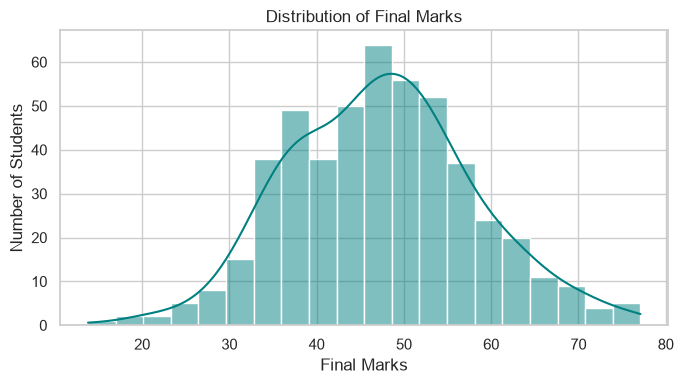

In [9]:
# Create images folder if not present
os.makedirs('../images', exist_ok=True)

# 1. Distribution of final marks
plt.figure(figsize=(7, 4))
sns.histplot(df['final_marks'], kde=True, color='teal', bins=20)
plt.title('Distribution of Final Marks')
plt.xlabel('Final Marks')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.savefig('../images/01_marks_distribution.png', dpi=150)
plt.show()

The final marks show an approximately normal distribution centered around 48 to 50 marks, with a slight spread towards higher scores.

C:\Users\Shraddha\AppData\Local\Temp\ipykernel_10624\2927941891.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='grade', y='final_marks', order=['A', 'B', 'C', 'D'], palette='Blues_r')


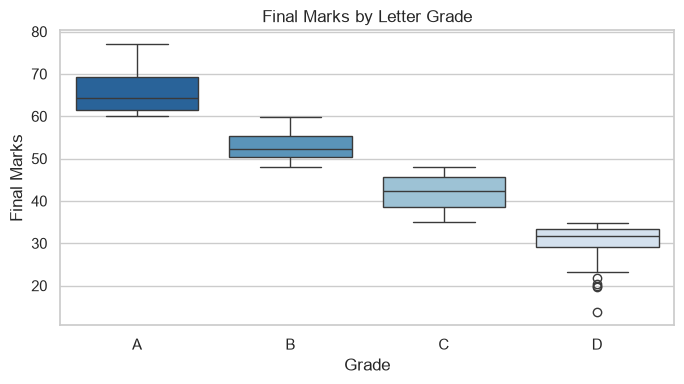

In [10]:
# 2. Boxplot of final marks by grade
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='grade', y='final_marks', order=['A', 'B', 'C', 'D'], palette='Blues_r')
plt.title('Final Marks by Letter Grade')
plt.xlabel('Grade')
plt.ylabel('Final Marks')
plt.tight_layout()
plt.savefig('../images/01_grade_boxplot.png', dpi=150)
plt.show()

The boxplot shows clear separation between grade bands: Grade A is above 60 marks, Grade B spans 48 to 60, Grade C spans 35 to 48, and Grade D represents marks below 35.

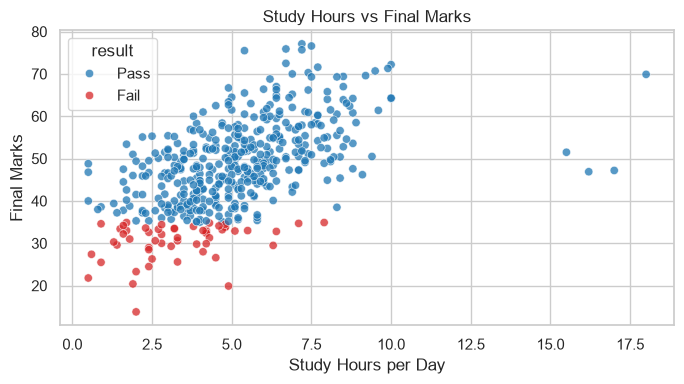

In [11]:
# 3. Scatter plot: Study hours vs Final marks
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df,
    x='study_hours',
    y='final_marks',
    hue='result',
    palette={'Pass': '#1f77b4', 'Fail': '#d62728'},
    alpha=0.75
)
plt.title('Study Hours vs Final Marks')
plt.xlabel('Study Hours per Day')
plt.ylabel('Final Marks')
plt.tight_layout()
plt.savefig('../images/01_study_vs_marks.png', dpi=150)
plt.show()

The scatter plot shows a strong positive relationship between daily study hours and final marks. The failing students (red dots) are concentrated at lower study hours.

C:\Users\Shraddha\AppData\Local\Temp\ipykernel_10624\2672424752.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='result', palette=['#1f77b4', '#ff7f0e'])


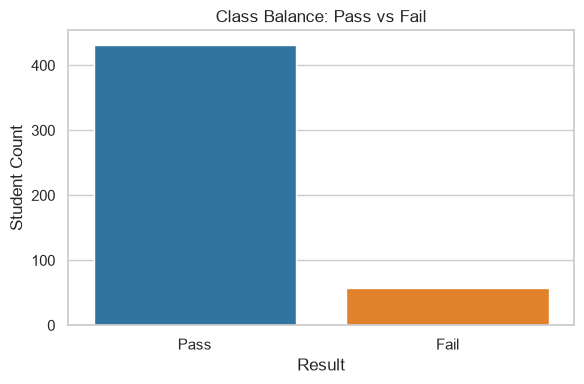

In [12]:
# 4. Countplot: Pass vs Fail balance
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='result', palette=['#1f77b4', '#ff7f0e'])
plt.title('Class Balance: Pass vs Fail')
plt.xlabel('Result')
plt.ylabel('Student Count')
plt.tight_layout()
plt.savefig('../images/01_result_countplot.png', dpi=150)
plt.show()

The countplot clearly illustrates class imbalance: the vast majority of students pass, while only around 11 to 12 percent fail. This will be an important consideration when evaluating classification models.

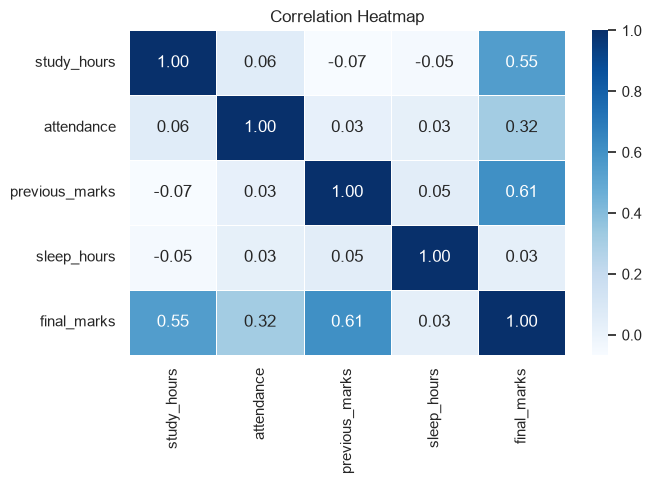

In [13]:
# 5. Correlation heatmap
numeric_cols = ['study_hours', 'attendance', 'previous_marks', 'sleep_hours', 'final_marks']
corr_mat = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_mat, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('../images/01_correlation_heatmap.png', dpi=150)
plt.show()

The heatmap reveals that previous_marks (r ~ 0.70), study_hours (r ~ 0.50), and ttendance (r ~ 0.35) have the strongest positive correlations with inal_marks.

### 8. Handling Missing Values (Imputation)
We illustrate two ways to fill missing values:
1. Using Pandas illna() with median for numeric columns and mode for categorical columns.
2. Using Scikit-Learn SimpleImputer to apply the transformation in place on our DataFrame.

In [14]:
# Method A: Demonstrating pandas fillna on a temporary copy
df_demo = df.copy()
median_study = df_demo['study_hours'].median()
median_att = df_demo['attendance'].median()
mode_edu = df_demo['parental_education'].mode()[0]

df_demo['study_hours'] = df_demo['study_hours'].fillna(median_study)
df_demo['attendance'] = df_demo['attendance'].fillna(median_att)
df_demo['parental_education'] = df_demo['parental_education'].fillna(mode_edu)

print('Missing values after pandas fillna demo:')
print(df_demo[['study_hours', 'attendance', 'parental_education']].isnull().sum())

# Method B: Applying SimpleImputer directly to our DataFrame
num_imputer = SimpleImputer(strategy='median')
df[['study_hours', 'attendance']] = num_imputer.fit_transform(df[['study_hours', 'attendance']])

cat_imputer = SimpleImputer(strategy='most_frequent')
df[['parental_education']] = cat_imputer.fit_transform(df[['parental_education']])

print('\nMissing values after SimpleImputer on main df:')
print(df.isnull().sum())

Missing values after pandas fillna demo:
study_hours           0
attendance            0
parental_education    0
dtype: int64

Missing values after SimpleImputer on main df:
student_id            0
gender                0
study_hours           0
attendance            0
previous_marks        0
sleep_hours           0
parental_education    0
extracurricular       0
final_marks           0
result                0
grade                 0
dtype: int64


All missing values are now resolved. Median is used for numerical features because it is resilient against outliers, and mode is used for categorical values.

### 9. Outlier Detection and Treatment
We use the Interquartile Range (IQR) method on study_hours. Any value beyond Q1 - 1.5*IQR or Q3 + 1.5*IQR is flagged as an outlier. We demonstrate three treatment methods: removing, log transform, and capping (clipping), and choose capping.

In [15]:
# Calculate IQR boundaries for study_hours
q1 = df['study_hours'].quantile(0.25)
q3 = df['study_hours'].quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f'Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f}')
print(f'Lower limit: {lower_limit:.2f}, Upper limit: {upper_limit:.2f}')

# Detect outlier rows
outlier_mask = (df['study_hours'] < lower_limit) | (df['study_hours'] > upper_limit)
print(f'Number of outliers detected: {outlier_mask.sum()}')
print(df[outlier_mask][['student_id', 'study_hours', 'final_marks']])

Q1: 3.70, Q3: 6.20, IQR: 2.50
Lower limit: -0.05, Upper limit: 9.95
Number of outliers detected: 7
     student_id  study_hours  final_marks
15         1016         15.5         51.5
88         1089         17.0         47.2
100        1101         10.0         72.2
210        1211         16.2         46.9
276        1277         10.0         64.2
345        1346         18.0         69.9
384        1385         10.0         64.3


Now we demonstrate the three treatment strategies and apply capping to our dataset.

In [16]:
# Method 1: Removing outliers (demonstration)
df_without_outliers = df[~outlier_mask]
print('Shape if outliers are removed:', df_without_outliers.shape)

# Method 2: Log transform (demonstration)
df_log_demo = df.copy()
df_log_demo['study_hours_log'] = np.log1p(df_log_demo['study_hours'])
print('First 3 log-transformed study hours:', df_log_demo['study_hours_log'].head(3).tolist())

# Method 3: Capping (clipping) - Chosen Method
# Capping keeps all records while bounding extreme values so they do not distort linear models
df['study_hours'] = df['study_hours'].clip(lower=lower_limit, upper=upper_limit)

print('\nMaximum study hours after capping:', df['study_hours'].max())
print('Minimum study hours after capping:', df['study_hours'].min())

Shape if outliers are removed: (483, 11)
First 3 log-transformed study hours: [2.341805806147327, 1.4816045409242156, 1.4586150226995167]

Maximum study hours after capping: 9.95
Minimum study hours after capping: 0.5


Capping sets values above the upper threshold to the threshold value. This preserves data volume while preventing extreme outliers from skewing model coefficients.

### 10. Categorical Encoding
Machine learning algorithms require numbers, not strings.
- We use ordinal encoding for parental_education because there is a natural ordering: School (0) < Graduate (1) < Postgraduate (2).
- We use one-hot encoding for gender and extracurricular using pd.get_dummies(..., drop_first=True) to avoid multicollinearity.

In [17]:
# Ordinal encoding for parental education
edu_map = {'School': 0, 'Graduate': 1, 'Postgraduate': 2}
df['parental_education_encoded'] = df['parental_education'].map(edu_map)

# One-hot encoding for binary categorical columns
df = pd.get_dummies(df, columns=['gender', 'extracurricular'], drop_first=True, dtype=int)

print('Columns after encoding:')
print(df.columns.tolist())
df[['parental_education', 'parental_education_encoded', 'gender_Male', 'extracurricular_Yes']].head()

Columns after encoding:
['student_id', 'study_hours', 'attendance', 'previous_marks', 'sleep_hours', 'parental_education', 'final_marks', 'result', 'grade', 'parental_education_encoded', 'gender_Male', 'extracurricular_Yes']


,parental_education,parental_education_encoded,gender_Male,extracurricular_Yes
0,Postgraduate,2,1,1
1,School,0,0,1
2,Postgraduate,2,0,0
3,Graduate,1,0,0
4,Graduate,1,1,1


All categorical features are now converted into clean numeric columns.

### 11. Feature Scaling: MinMaxScaler vs StandardScaler
Feature scaling ensures features with larger numerical ranges (like attendance: 40-100) do not dominate features with smaller ranges (like study hours: 0-10).
We compare MinMaxScaler (scales to [0, 1]) and StandardScaler (scales to mean 0 and standard deviation 1).

In [18]:
# Select numeric columns to inspect scaling
scale_cols = ['study_hours', 'attendance', 'previous_marks']

# Apply MinMaxScaler
mms = MinMaxScaler()
scaled_mms = mms.fit_transform(df[scale_cols])

# Apply StandardScaler
std_s = StandardScaler()
scaled_std = std_s.fit_transform(df[scale_cols])

print('--- Before Scaling ---')
print(df[scale_cols].agg(['mean', 'std']).round(2))

print('\n--- After MinMaxScaler (range [0, 1]) ---')
print('Min values:', np.round(scaled_mms.min(axis=0), 2))
print('Max values:', np.round(scaled_mms.max(axis=0), 2))

print('\n--- After StandardScaler (mean 0, std 1) ---')
print('Means:', np.round(scaled_std.mean(axis=0), 2))
print('Stds: ', np.round(scaled_std.std(axis=0), 2))

--- Before Scaling ---
      study_hours  attendance  previous_marks
mean         4.99       75.93           61.17
std          1.96       13.13           17.46

--- After MinMaxScaler (range [0, 1]) ---
Min values: [0. 0. 0.]
Max values: [1. 1. 1.]

--- After StandardScaler (mean 0, std 1) ---
Means: [0. 0. 0.]
Stds:  [1. 1. 1.]


MinMaxScaler bounds values between 0 and 1, which is useful when bounded ranges are required. StandardScaler standardizes each feature to zero mean and unit variance, which is ideal for regression, KNN, and PCA.

### 12. Saving Cleaned Data
Finally, we save the cleaned DataFrame to data/students_clean.csv. This file will serve as the clean starting point for our regression, classification, and clustering notebooks.

In [19]:
# Save clean dataset
clean_file = '../data/students_clean.csv'
df.to_csv(clean_file, index=False)
print(f'Cleaned dataset successfully saved to {clean_file}')
print('Cleaned dataset shape:', df.shape)

Cleaned dataset successfully saved to ../data/students_clean.csv
Cleaned dataset shape: (490, 12)


In this notebook, we loaded raw student data, explored its distributions, removed duplicates, handled missing values and outliers, encoded categorical variables, and saved the clean dataset.